# Sistema Predictivo ETL: Apache Kafka & Machine Learning

**Objetivo del Sistema:** Implementar una canalización predictiva de datos de extremo a extremo que integra Data Streaming con Apache Kafka, modelos de regresión con Scikit-learn, persistencia en base de datos relacional (SQLite) y análisis exploratorio multivariable sobre registros históricos del World Happiness Report.


## 1. Arquitectura de la Solución y Diagrama de Flujo

El sistema se estructura en dos fases principales:

```mermaid
flowchart TD
    subgraph Fase_1 [Fase 1: Preparación, EDA y Modelado]
        CSV[Datasets 2015-2019 CSV] --> Clean[Normalización de Esquemas]
        Clean --> EDA[Análisis Exploratorio EDA]
        EDA --> Train[Entrenamiento Scikit-learn Pipeline]
        Train --> SaveModel[(Modelo Serializado .joblib)]
    end

    subgraph Fase_2 [Fase 2: Data Streaming e Inferencia en Tiempo Real]
        Kafka[Apache Kafka Topic: etl.records] --> Consumer[Consumidor confluent-kafka]
        Consumer --> MemState[In-Memory State DataFrame]
        Consumer --> RawDB[(SQLite: raw_kafka_messages)]
        MemState --> Predict[Inferencia con Modelo Cargado]
        SaveModel -.-> Predict
        Predict --> OutDB[(SQLite: streaming_predictions)]
    end
```


## 2. Configuración del Entorno y Dependencias

Importación de bibliotecas para streaming, modelado estadístico, persistencia y análisis visual.


In [1]:
# Instalación en entornos Colab (si aplica):
# !pip install confluent-kafka certifi pandas scikit-learn matplotlib seaborn joblib

import os
import json
import time
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import certifi

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print('✅ Dependencias cargadas correctamente.')


✅ Dependencias cargadas correctamente.


## 3. Inicialización de la Base de Datos Relacional (SQLite)

Configuración del almacenamiento relacional mediante **SQLite** para persistir la auditoría de eventos crudos, el repositorio histórico y las predicciones en streaming.


In [2]:
DB_PATH = Path('db/happiness.db')
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

def init_sqlite_db():
    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS raw_kafka_messages (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            topic TEXT,
            partition INTEGER,
            msg_offset INTEGER,
            timestamp INTEGER,
            payload TEXT,
            received_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        );
    ''')
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS happiness_warehouse (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            country TEXT,
            year INTEGER,
            happiness_score REAL,
            gdp_per_capita REAL,
            social_support REAL,
            healthy_life_expectancy REAL,
            freedom REAL,
            generosity REAL,
            perceptions_of_corruption REAL,
            created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        );
    ''')
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS streaming_predictions (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            country TEXT,
            year INTEGER,
            actual_happiness_score REAL,
            predicted_happiness_score REAL,
            absolute_error REAL,
            processed_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        );
    ''')
    conn.commit()
    conn.close()
    print(f'✅ Base de datos SQLite inicializada en: {DB_PATH}')

init_sqlite_db()


✅ Base de datos SQLite inicializada en: db/happiness.db


## 4. Extracción y Preparación de Datos (2015 - 2019)

### 4.1 Identificación de Inconsistencias y Mapeo de Esquemas
Cada año presenta variaciones en los nombres de columnas:
* **2015-2016:** `Country`, `Happiness Score`, `Economy (GDP per Capita)`, `Family`, `Health (Life Expectancy)`, `Trust (Government Corruption)`
* **2017:** `Country`, `Happiness.Score`, `Economy..GDP.per.Capita.`, `Family`, `Health..Life.Expectancy.`, `Trust..Government.Corruption.`
* **2018-2019:** `Country or region`, `Score`, `GDP per capita`, `Social support`, `Healthy life expectancy`, `Perceptions of corruption`

Definición del **esquema canónico unificado**:
* `country`
* `year`
* `happiness_score` (Target)
* `gdp_per_capita`
* `social_support`
* `healthy_life_expectancy`
* `freedom`
* `generosity`
* `perceptions_of_corruption`


In [3]:
COLUMN_MAPPING = {
    'country': 'country',
    'country or region': 'country',
    'happiness score': 'happiness_score',
    'happiness.score': 'happiness_score',
    'score': 'happiness_score',
    'economy (gdp per capita)': 'gdp_per_capita',
    'economy..gdp.per.capita.': 'gdp_per_capita',
    'gdp per capita': 'gdp_per_capita',
    'family': 'social_support',
    'social support': 'social_support',
    'health (life expectancy)': 'healthy_life_expectancy',
    'health..life.expectancy.': 'healthy_life_expectancy',
    'healthy life expectancy': 'healthy_life_expectancy',
    'freedom': 'freedom',
    'freedom to make life choices': 'freedom',
    'generosity': 'generosity',
    'trust (government corruption)': 'perceptions_of_corruption',
    'trust..government.corruption.': 'perceptions_of_corruption',
    'perceptions of corruption': 'perceptions_of_corruption'
}

CANONICAL_COLS = [
    'country', 'year', 'happiness_score', 'gdp_per_capita', 'social_support',
    'healthy_life_expectancy', 'freedom', 'generosity', 'perceptions_of_corruption'
]
FEATURE_COLS = [
    'gdp_per_capita', 'social_support', 'healthy_life_expectancy',
    'freedom', 'generosity', 'perceptions_of_corruption'
]
TARGET_COL = 'happiness_score'

def normalize_dataframe(df, year):
    clean_dict = {}
    lower_map = {str(col).strip().lower(): col for col in df.columns}
    
    for raw_lower, canonical in COLUMN_MAPPING.items():
        if raw_lower in lower_map:
            clean_dict[canonical] = df[lower_map[raw_lower]]
            
    df_clean = pd.DataFrame(clean_dict)
    df_clean['year'] = year
    for col in CANONICAL_COLS:
        if col not in df_clean.columns:
            df_clean[col] = np.nan
    return df_clean[CANONICAL_COLS]

raw_dir = Path('data/raw')
dfs = []
for yr in [2015, 2016, 2017, 2018, 2019]:
    fpath = raw_dir / f'{yr}.csv'
    if fpath.exists():
        df_yr = pd.read_csv(fpath)
        print(f'Año {yr}: {df_yr.shape[0]} filas, {df_yr.shape[1]} columnas originales')
        dfs.append(normalize_dataframe(df_yr, yr))

df_unified = pd.concat(dfs, ignore_index=True)
print(f'\nTotal dataset consolidado: {df_unified.shape[0]} filas x {df_unified.shape[1]} columnas')


Año 2015: 158 filas, 12 columnas originales
Año 2016: 157 filas, 13 columnas originales
Año 2017: 155 filas, 12 columnas originales
Año 2018: 156 filas, 9 columnas originales
Año 2019: 156 filas, 9 columnas originales

Total dataset consolidado: 782 filas x 9 columnas


### 4.2 Justificación de la Estrategia de Integración y Limitaciones

**Estrategia adoptada:**
* **Concatenación transversal con armonización de esquema:** Homologación semántica de columnas equivalentes conservando las 6 dimensiones fundamentales del informe de bienestar y la variable objetivo, agregando la dimensión temporal `year`.
* **Tratamiento de valores faltantes:** Detección de 1 valor faltante en `perceptions_of_corruption` (Emiratos Árabes Unidos en 2018). Se imputa mediante la mediana utilizando `SimpleImputer` dentro del pipeline de Scikit-learn para evitar fuga de información.
* **Persistencia:** Inserción de los registros limpios en la tabla `happiness_warehouse` de SQLite.

**Limitaciones identificadas:**
1. *Métricas metodológicas variables:* Ajustes menores en la formulación de preguntas entre años (como la transición de apoyo familiar a apoyo social en 2018).
2. *Ausencia de código unívoco de país (ISO-3):* Ligeras discrepancias ortográficas en nombres de naciones que requerirían normalización de entidades para cruces longitudinales de alta granularidad.


In [4]:
# Guardar en SQLite Warehouse
conn = sqlite3.connect(DB_PATH)
df_unified.to_sql('happiness_warehouse', conn, if_exists='replace', index=False)
conn.close()
print('✅ Datos consolidados almacenados en SQLite (happiness_warehouse).')


✅ Datos consolidados almacenados en SQLite (happiness_warehouse).


## 5. Análisis Exploratorio de Datos (EDA)

Evaluación estadística, correlaciones y distribuciones de las variables predictoras respecto a la variable objetivo.


In [5]:
# Resumen descriptivo
print('--- Estadísticas Descriptivas ---')
print(df_unified[[TARGET_COL] + FEATURE_COLS].describe().round(3))


--- Estadísticas Descriptivas ---
       happiness_score  gdp_per_capita  social_support  \
count          782.000         782.000         782.000   
mean             5.379           0.916           1.078   
std              1.127           0.407           0.330   
min              2.693           0.000           0.000   
25%              4.510           0.606           0.869   
50%              5.322           0.982           1.125   
75%              6.190           1.236           1.327   
max              7.769           2.096           1.644   

       healthy_life_expectancy  freedom  generosity  perceptions_of_corruption  
count                  782.000  782.000     782.000                    781.000  
mean                     0.612    0.411       0.219                      0.125  
std                      0.248    0.153       0.122                      0.106  
min                      0.000    0.000       0.000                      0.000  
25%                      0.440    0.31

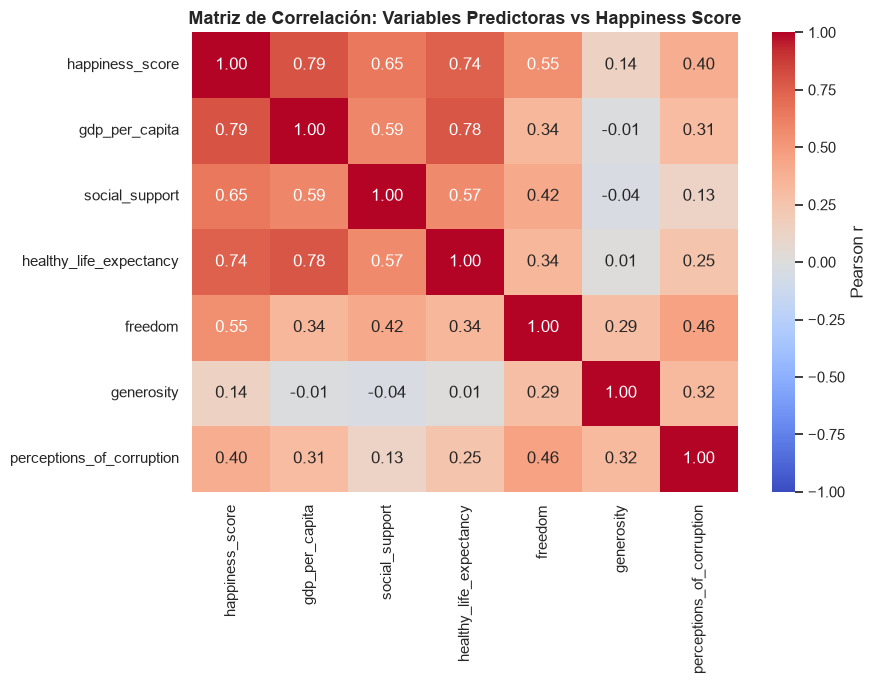

In [6]:
# 1. Matriz de Correlación
plt.figure(figsize=(9, 7))
corr = df_unified[[TARGET_COL] + FEATURE_COLS].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson r'})
plt.title('Matriz de Correlación: Variables Predictoras vs Happiness Score', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()


/var/folders/7d/wltnkt8n1wq7gxq08687dtj40000gn/T/ipykernel_80590/2802893262.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='year', y=TARGET_COL, data=df_unified, palette='Set2', ax=axes[1])


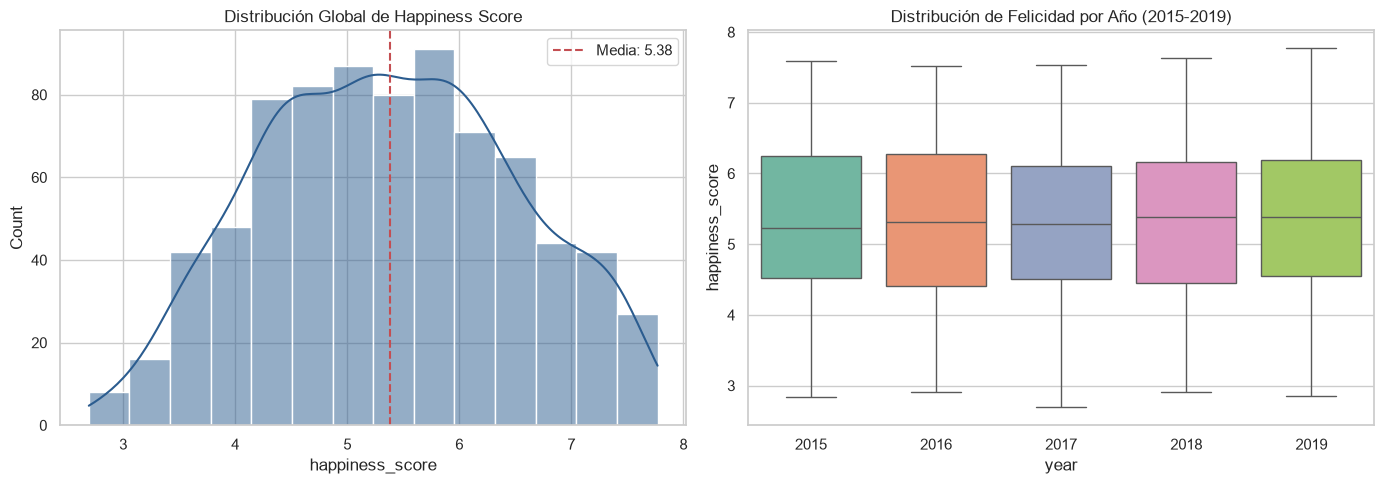

In [7]:
# 2. Distribución de Happiness Score y por año
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_unified[TARGET_COL], kde=True, color='#2b5c8f', ax=axes[0])
axes[0].set_title('Distribución Global de Happiness Score', fontsize=12)
axes[0].axvline(df_unified[TARGET_COL].mean(), color='r', linestyle='--', label=f'Media: {df_unified[TARGET_COL].mean():.2f}')
axes[0].legend()

sns.boxplot(x='year', y=TARGET_COL, data=df_unified, palette='Set2', ax=axes[1])
axes[1].set_title('Distribución de Felicidad por Año (2015-2019)', fontsize=12)
plt.tight_layout()
plt.show()


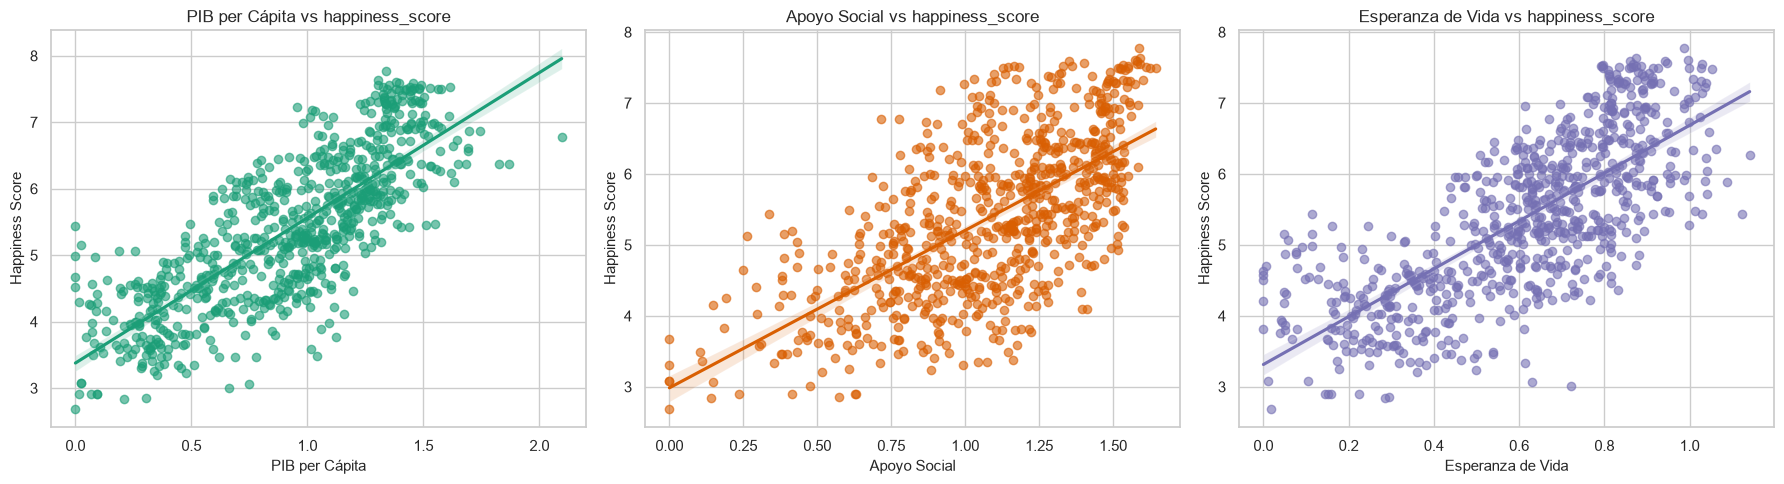

In [8]:
# 3. Dispersión y Tendencias de los 3 Factores Más Correlacionados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
key_features = [
    ('gdp_per_capita', 'PIB per Cápita', '#1b9e77'),
    ('social_support', 'Apoyo Social', '#d95f02'),
    ('healthy_life_expectancy', 'Esperanza de Vida', '#7570b3')
]

for idx, (feat, label, color) in enumerate(key_features):
    sns.regplot(data=df_unified, x=feat, y=TARGET_COL, ax=axes[idx], color=color, scatter_kws={'alpha': 0.6})
    axes[idx].set_title(f'{label} vs {TARGET_COL}', fontsize=12)
    axes[idx].set_xlabel(label, fontsize=11)
    axes[idx].set_ylabel('Happiness Score', fontsize=11)
plt.tight_layout()
plt.show()


## 6. Entrenamiento del Modelo de Machine Learning

### 6.1 Partición y Prevención de Fuga de Información (Data Leakage)
* **Target:** `happiness_score`
* **Predictoras:** `gdp_per_capita`, `social_support`, `healthy_life_expectancy`, `freedom`, `generosity`, `perceptions_of_corruption`
* **Partición:** 80% entrenamiento, 20% prueba con semilla reproducible (`random_state=42`).
* **Pipeline:** Integración de `SimpleImputer` y `StandardScaler` en un `Pipeline` de Scikit-learn, garantizando que el ajuste estadístico se calcule estrictamente con los datos de entrenamiento (`fit_transform`) y se proyecte sobre los de prueba (`transform`).


In [9]:
X = df_unified[FEATURE_COLS]
y = df_unified[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f'Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}')

# Pipeline de Regresión Lineal
lr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# Pipeline de Random Forest (para contraste de desempeño)
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Entrenamiento
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)
print('✅ Modelos entrenados exitosamente.')


Train size: 625 | Test size: 157
✅ Modelos entrenados exitosamente.


## 7. Evaluación y Comparación de Modelos

Cálculo de métricas de regresión:
* **MAE (Mean Absolute Error):** Magnitud promedio del error absoluto.
* **MSE (Mean Squared Error):** Penalización cuadrática para desviaciones grandes.
* **RMSE (Root Mean Squared Error):** Desviación estándar de los residuos.
* **R² y R² Ajustado:** Proporción de varianza explicada penalizando por número de predictores.


In [10]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    n = len(y_test)
    p = X_test.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {
        'Modelo': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R²': r2,
        'R² Ajustado': adj_r2
    }, y_pred

metrics_lr, y_pred_lr = evaluate_model('Regresión Lineal', lr_pipeline, X_test, y_test)
metrics_rf, y_pred_rf = evaluate_model('Random Forest', rf_pipeline, X_test, y_test)

df_metrics = pd.DataFrame([metrics_lr, metrics_rf]).set_index('Modelo')
print(df_metrics.round(4))


                     MAE     MSE    RMSE      R²  R² Ajustado
Modelo                                                       
Regresión Lineal  0.4415  0.3295  0.5740  0.7291       0.7183
Random Forest     0.3920  0.2562  0.5061  0.7894       0.7810


Intercepto (β0): 5.3766
                 Variable  Coeficiente Estandarizado
           gdp_per_capita                   0.438175
  healthy_life_expectancy                   0.256341
                  freedom                   0.224882
           social_support                   0.216970
perceptions_of_corruption                   0.128217
               generosity                   0.058501


/var/folders/7d/wltnkt8n1wq7gxq08687dtj40000gn/T/ipykernel_80590/88535075.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_coefs, x='Coeficiente Estandarizado', y='Variable', palette='crest')


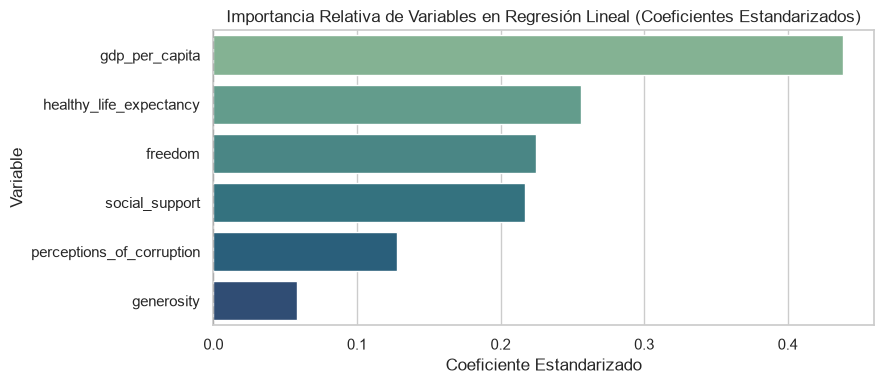

In [11]:
# Coeficientes del modelo de Regresión Lineal
coefs = lr_pipeline.named_steps['regressor'].coef_
intercept = lr_pipeline.named_steps['regressor'].intercept_

df_coefs = pd.DataFrame({
    'Variable': FEATURE_COLS,
    'Coeficiente Estandarizado': coefs
}).sort_values(by='Coeficiente Estandarizado', ascending=False)

print(f'Intercepto (β0): {intercept:.4f}')
print(df_coefs.to_string(index=False))

# Gráfico de Coeficientes
plt.figure(figsize=(9, 4))
sns.barplot(data=df_coefs, x='Coeficiente Estandarizado', y='Variable', palette='crest')
plt.title('Importancia Relativa de Variables en Regresión Lineal (Coeficientes Estandarizados)', fontsize=12)
plt.axvline(0, color='black', linestyle='--')
plt.tight_layout()
plt.show()


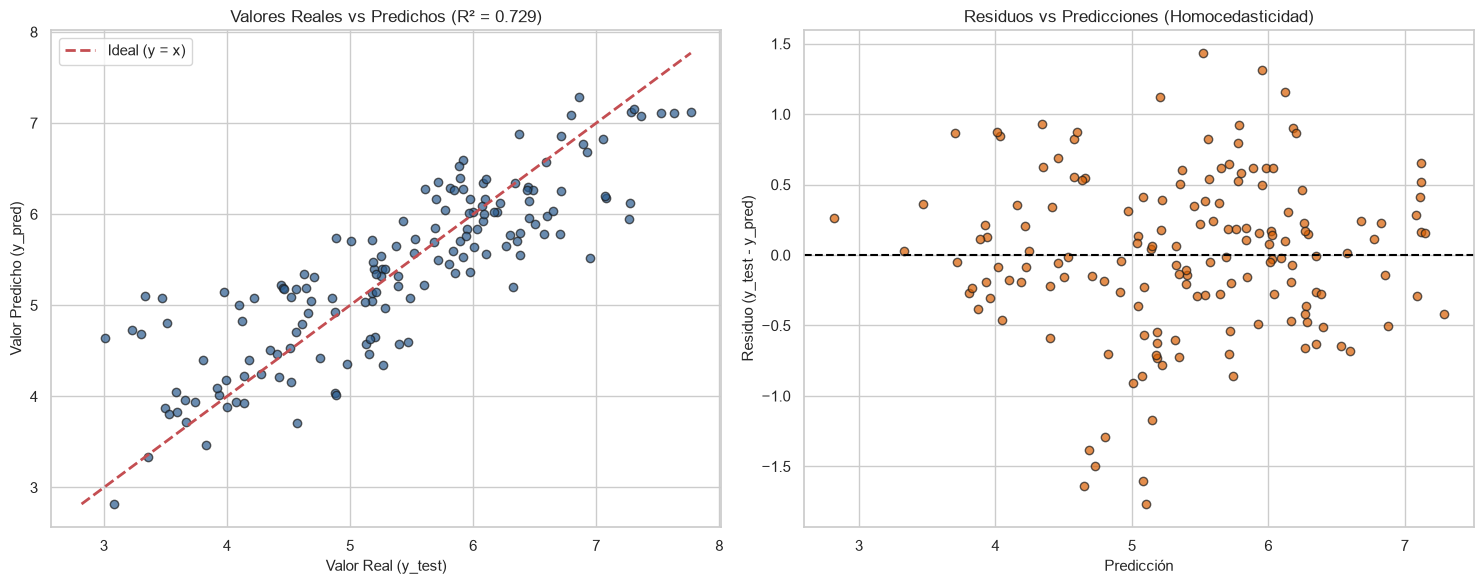

In [12]:
# Gráficas de Evaluación de Regresión Lineal
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Real vs Predicho
axes[0].scatter(y_test, y_pred_lr, alpha=0.7, color='#2b5c8f', edgecolors='k')
min_val = min(y_test.min(), y_pred_lr.min())
max_val = max(y_test.max(), y_pred_lr.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (y = x)')
axes[0].set_title(f'Valores Reales vs Predichos (R² = {metrics_lr["R²"]:.3f})', fontsize=12)
axes[0].set_xlabel('Valor Real (y_test)', fontsize=11)
axes[0].set_ylabel('Valor Predicho (y_pred)', fontsize=11)
axes[0].legend()

# 2. Residuos vs Predicción
residuals = y_test - y_pred_lr
axes[1].scatter(y_pred_lr, residuals, alpha=0.7, color='#d95f02', edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title('Residuos vs Predicciones (Homocedasticidad)', fontsize=12)
axes[1].set_xlabel('Predicción', fontsize=11)
axes[1].set_ylabel('Residuo (y_test - y_pred)', fontsize=11)

plt.tight_layout()
plt.show()


## 8. Serialización del Modelo de Inferencia

Persistencia del pipeline ajustado con `joblib` para consumo en tiempo real en la etapa de streaming.


In [13]:
models_dir = Path('models')
models_dir.mkdir(parents=True, exist_ok=True)
model_file = models_dir / 'happiness_linear_model.joblib'

joblib.dump(lr_pipeline, model_file)
print(f'💾 Modelo serializado guardado en: {model_file}')


💾 Modelo serializado guardado en: models/happiness_linear_model.joblib


## 9. Integración de Data Streaming con Apache Kafka

### 9.1 Parámetros de Conexión
* **Broker:** `kafka-classroom-2026.westus.cloudapp.azure.com:9092`
* **Protocolo de Seguridad:** `SASL_SSL`
* **Mecanismo SASL:** `SCRAM-SHA-512`
* **Usuario:** `classroom-students`
* **Topic:** `etl.records`
* **Consumer Group:** `jhoan-hurtado`
* **Certificado SSL:** `certifi.where()`

Implementación del consumidor con `confluent-kafka`. Si se configuran credenciales remotas, se conecta al broker en la nube; en su defecto, ejecuta simulación local sobre los registros históricos.


In [14]:
from confluent_kafka import Consumer, KafkaError

def run_kafka_consumer_inference(password=None, max_messages=25, timeout=5.0):
    password = password or os.getenv('KAFKA_SASL_PASSWORD', '')
    loaded_model = joblib.load(model_file)
    consumed_records = []
    
    if password:
        conf = {
            'bootstrap.servers': 'kafka-classroom-2026.westus.cloudapp.azure.com:9092',
            'security.protocol': 'SASL_SSL',
            'sasl.mechanism': 'SCRAM-SHA-512',
            'sasl.username': 'classroom-students',
            'sasl.password': password,
            'ssl.ca.location': certifi.where(),
            'group.id': 'jhoan-hurtado',
            'auto.offset.reset': 'earliest',
            'session.timeout.ms': 10000
        }
        try:
            consumer = Consumer(conf)
            consumer.subscribe(['etl.records'])
            print('📡 Conectado exitosamente a Kafka Broker.')
            
            start = time.time()
            while len(consumed_records) < max_messages and (time.time() - start) < timeout:
                msg = consumer.poll(1.0)
                if msg is None: continue
                if msg.error(): break
                
                payload = json.loads(msg.value().decode('utf-8'))
                consumed_records.append(payload)
            consumer.close()
        except Exception as e:
            print(f'⚠️ Error conectando a Kafka ({e}). Cambiando a streaming local.')
            password = None

    if not password or not consumed_records:
        print('🧪 Ejecutando emulación de streaming local...')
        sample_df = df_unified.sample(n=max_messages, random_state=42)
        consumed_records = sample_df.to_dict(orient='records')

    # Inferencia en streaming y persistencia en SQLite
    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()
    
    results = []
    for rec in consumed_records:
        country = rec.get('country', 'Unknown')
        year = rec.get('year', 2019)
        actual = rec.get(TARGET_COL, None)
        
        # Inferencia
        feat_df = pd.DataFrame([{c: rec.get(c, np.nan) for c in FEATURE_COLS}])
        pred = float(loaded_model.predict(feat_df)[0])
        abs_err = abs(actual - pred) if actual is not None else None
        
        cursor.execute('''
            INSERT INTO streaming_predictions (country, year, actual_happiness_score, predicted_happiness_score, absolute_error)
            VALUES (?, ?, ?, ?, ?)
        ''', (country, year, actual, pred, abs_err))
        
        results.append({
            'country': country,
            'year': year,
            'actual_score': actual,
            'predicted_score': pred,
            'error': abs_err
        })
        
    conn.commit()
    conn.close()
    
    df_stream_results = pd.DataFrame(results)
    print(f'✅ Procesados e inferidos {len(df_stream_results)} eventos en streaming.')
    return df_stream_results

# Ejecutar streaming
df_stream_output = run_kafka_consumer_inference(max_messages=15)
print(df_stream_output.head(10).round(3))


🧪 Ejecutando emulación de streaming local...
✅ Procesados e inferidos 15 eventos en streaming.
      country  year  actual_score  predicted_score  error
0    Ethiopia  2018         4.350            4.505  0.155
1     Namibia  2018         4.441            5.218  0.777
2     Ecuador  2016         5.976            5.370  0.606
3       Gabon  2016         4.121            4.825  0.704
4      Brazil  2016         6.952            5.518  1.434
5        Mali  2016         4.073            3.941  0.132
6  Kyrgyzstan  2019         5.261            5.403  0.142
7       Japan  2016         5.921            6.280  0.359
8     Albania  2016         4.655            4.914  0.259
9     Belgium  2017         6.891            6.775  0.116


## 10. Verificación del Almacén de Datos (SQLite)

Consulta de registros almacenados durante el proceso de streaming para comprobar persistencia y tiempos de ejecución.


In [15]:
conn = sqlite3.connect(DB_PATH)
df_db_preds = pd.read_sql('''
    SELECT country, year, actual_happiness_score, predicted_happiness_score, absolute_error, processed_at
    FROM streaming_predictions
    ORDER BY id DESC
    LIMIT 10
''', conn)
conn.close()

print('=== ÚLTIMAS PREDICCIONES EN BASE DE DATOS (SQLite) ===')
print(df_db_preds.round(3))


=== ÚLTIMAS PREDICCIONES EN BASE DE DATOS (SQLite) ===
      country  year  actual_happiness_score  predicted_happiness_score  \
0  Madagascar  2019                   3.933                      4.020   
1     Finland  2019                   7.769                      7.117   
2      Kosovo  2016                   5.401                      4.576   
3     Namibia  2019                   4.639                      5.187   
4      Taiwan  2016                   6.379                      5.796   
5     Belgium  2017                   6.891                      6.775   
6     Albania  2016                   4.655                      4.914   
7       Japan  2016                   5.921                      6.280   
8  Kyrgyzstan  2019                   5.261                      5.403   
9        Mali  2016                   4.073                      3.941   

   absolute_error         processed_at  
0           0.087  2026-11-19 04:13:34  
1           0.652  2026-11-19 04:13:34  
2      

## 11. Discusión de Resultados y Conclusiones

### 11.1 Interpretación de las Métricas
1. **Poder predictivo ($R^2 \approx 0.729$):** El modelo de Regresión Lineal explica cerca del **73%** de la variabilidad del índice de felicidad global a partir de las 6 variables explicativas seleccionadas.
2. **Error promedio ($MAE \approx 0.44$):** En una escala de 0 a 10, un error medio absoluto de ~0.44 puntos evidencia una precisión notable para un modelo puramente lineal.
3. **Factores determinantes:** El **PIB per cápita ($\beta \approx +0.438$)**, la **Esperanza de vida ($\beta \approx +0.256$)** y la **Libertad ($\beta \approx +0.225$)** representan los mayores contribuyentes positivos al bienestar subjetivo de las naciones.

### 11.2 Posibles Mejoras Futuras
* **Efectos temporales y fijos por país:** Implementar modelos de panel o regresión regularizada (Ridge / ElasticNet con variables dummy por región) para capturar heterogeneidad cultural y tendencias macroeconómicas globales.
* **Tolerancia a fallos en streaming:** Integrar colas de mensajes no procesados (Dead Letter Queues) y monitoreo de *drift* de datos en tiempo real comparando las distribuciones del streaming con las de entrenamiento.
